# Dengue Early-Warning System: reproducible modelling notebook
Runs locally (no Colab). Uses the project's `src/` modules so notebook, app and tests share one code path.

**Flow:** data audit -> lag features (+verification) -> EDA of the 2-4 week lag -> chronological split -> model & feature-set comparison -> test -> risk tiers, intervals, drivers.

In [1]:
import sys, json, warnings; warnings.filterwarnings('ignore')
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.features import load_raw, build_dataset, add_target, feature_sets
sns.set_theme(style='whitegrid')

## 1. Data audit

In [2]:
raw = load_raw()
print(raw.shape, raw.date.min().date(), raw.date.max().date(), raw.ward_id.nunique(), 'wards')
print('missing:', int(raw.isna().sum().sum()), '| duplicate ward-weeks:', int(raw.duplicated(['ward_id','date']).sum()))
print('weekly continuity per ward:', raw.groupby('ward_id').date.apply(lambda s: (s.diff().dropna()==pd.Timedelta(days=7)).all()).all())
print('zero-case share:', round((raw.dengue_cases==0).mean(),3))
raw.describe().T[['mean','std','min','max']]

(31320, 12) 2016-01-04 2025-12-29 60 wards
missing: 0 | duplicate ward-weeks: 0
weekly continuity per ward: True
zero-case share: 0.58


,mean,std,min,max
date,2020-12-31 12:00:00,NaN,2016-01-04 00:00:00,2025-12-29 00:00:00
population_density_sqkm,43157.733333,14865.377799,18314.0,74252.0
water_logging_risk_index,0.579333,0.237903,0.22,0.94
sanitation_score,0.554667,0.191597,0.25,0.88
avg_temp_c,26.922804,4.482042,15.74,37.51
max_temp_c,31.889061,4.516627,23.12,40.79
min_temp_c,21.949425,4.527965,13.06,31.64
rainfall_mm,35.630268,50.237519,0.0,268.83
relative_humidity_pct,71.176132,12.96861,41.84,99.0
dengue_cases,2.636398,4.607737,0.0,41.0


## 2. Ward-level lag / rolling features and verification
Lags, rolling windows and forecast targets are aligned on **(ward_id, calendar date)** with `features.value_at_offset`, never on row position, so a missing week produces NaN instead of silently borrowing a different week. Duplicate ward-week rows are rejected. The checks below fail loudly on leakage across wards or time.

In [3]:
from src.features import add_weather_features, add_target as _tgt
df = build_dataset(with_history=True)
x = df[df.ward_id=='CCC_Ward_01'].reset_index(drop=True)
assert np.allclose(x.rain_lag_3w[3:], x.rainfall_mm.shift(3)[3:])   # equal only because this dataset has no calendar gaps
assert x.rain_lag_3w[:3].isna().all()            # first weeks of a ward are NaN, not borrowed from another ward
# demonstration on a copy with ONE week deleted: calendar alignment gives NaN where the source week is missing
w = raw[raw.ward_id=='CCC_Ward_01'].reset_index(drop=True); gap_week = w.date[20]
g = add_weather_features(w[w.date != gap_week]).set_index('date')
print('rain_lag_1w the week after the deleted week (must be NaN):', g.loc[gap_week + pd.Timedelta(weeks=1), 'rain_lag_1w'])
print('rain_roll4w_sum for the 4 windows touching the gap:', g.loc[gap_week + pd.Timedelta(weeks=1): gap_week + pd.Timedelta(weeks=3), 'rain_roll4w_sum'].tolist())
print('lag checks passed; feature table', df.shape)
print({k: len(v) for k, v in feature_sets(df).items()}, 'features per configuration')

rain_lag_1w the week after the deleted week (must be NaN): nan
rain_roll4w_sum for the 4 windows touching the gap: [nan, nan, nan]
lag checks passed; feature table (31320, 58)
{'weather_only': 47, 'weather_no_static': 44, 'weather_plus_history': 52} features per configuration


## 3. The 2-4 week breeding clock in the data

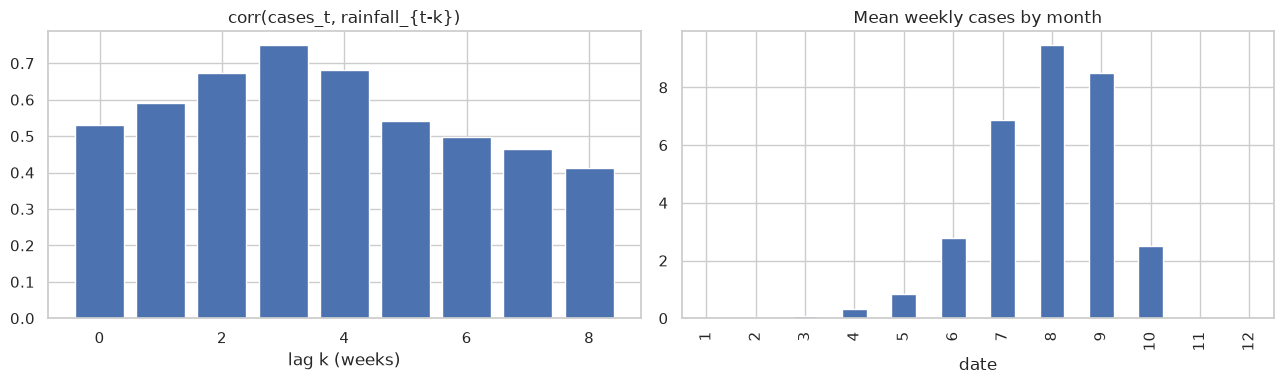

peak lag: 3 weeks


In [4]:
d = raw.copy(); g = d.groupby('ward_id')
lag_corr = {k: d.dengue_cases.corr(g.rainfall_mm.shift(k)) for k in range(0, 9)}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(list(lag_corr), list(lag_corr.values())); ax[0].set_title('corr(cases_t, rainfall_{t-k})'); ax[0].set_xlabel('lag k (weeks)')
raw.groupby(raw.date.dt.month).dengue_cases.mean().plot.bar(ax=ax[1], title='Mean weekly cases by month'); plt.tight_layout(); plt.show()
print('peak lag:', max(lag_corr, key=lag_corr.get), 'weeks')

## 4. Chronological split (4-week purge gap)

In [5]:
from src.train import split_masks
y = add_target(df); tr, va, ts = split_masks(df, y)
okf = df[feature_sets(df)['weather_only']].notna().all(axis=1)
for n, m in [('train', tr&okf), ('val', va&okf), ('test', ts&okf)]:
    print(f"{n:5s} {df.loc[m,'date'].min().date()} -> {df.loc[m,'date'].max().date()}  rows={int(m.sum())}")

train 2016-02-29 -> 2022-11-28  rows=21180
val   2023-01-02 -> 2024-05-27  rows=4440
test  2024-07-01 -> 2025-12-01  rows=4500


## 5. Train, compare, select, evaluate
`src.train.main()` runs the whole experiment (~3-4 min): model x feature-set comparison on validation, per-window calibration on chronological out-of-fold forecasts, a single test evaluation, and the original-vs-improved comparison. Set `RETRAIN = True` to re-run it (this overwrites `reports/` and `models/`); by default the notebook reads the committed reports.

In [6]:
RETRAIN = False
if RETRAIN:
    from src.train import main
    main()
else:
    print('Reading committed reports (set RETRAIN=True to regenerate).')

Reading committed reports (set RETRAIN=True to regenerate).


### Validation comparison (main window: cases summed over weeks 2-4 ahead)

In [7]:
pd.read_csv(ROOT/'reports/model_comparison_validation.csv').round(3)

,features,model,n_val,MAE,RMSE,R2
0,weather_plus_history,HistGB (Poisson),4440,1.844,3.864,0.916
1,weather_only,HistGB (Poisson),4440,1.856,3.891,0.915
2,weather_plus_history,HistGB (squared),4440,1.865,3.799,0.919
3,weather_only,HistGB (squared),4440,1.881,3.838,0.917
4,weather_only,RandomForest,4440,1.966,4.023,0.909
5,weather_plus_history,ExtraTrees,4440,2.031,4.151,0.903
6,weather_only,ExtraTrees,4440,2.045,4.201,0.900
7,weather_no_static,HistGB (Poisson),4440,2.488,5.526,0.828
8,weather_no_static,HistGB (squared),4440,2.592,5.547,0.826
9,weather_no_static,ExtraTrees,4440,2.602,5.609,0.822


**Findings.** Static ward attributes matter (removing them raises validation MAE sharply). Reported-case history adds nothing beyond weather + ward attributes, so the weather-only model is chosen (also deployable to wards with no surveillance).

In [8]:
M = json.loads((ROOT/'reports/metrics.json').read_text())
print('selected:', M['selected'])
pd.DataFrame(M['test_by_window']).T[['n','MAE','RMSE','R2','interval_coverage','interval_width','tier_exact_accuracy','tier_within_one','HC_recall','HC_precision','HC_F1','HC_false_alarm_rate']].round(3)

selected: {'model': 'HistGB (Poisson)', 'features': 'weather_only', 'history_adopted': False, 'n_features': 47}


,n,MAE,RMSE,R2,interval_coverage,interval_width,tier_exact_accuracy,tier_within_one,HC_recall,HC_precision,HC_F1,HC_false_alarm_rate
Weeks 2-4 ahead (total),4500,2.63862,4.920475,0.81296,0.910444,11.924583,0.805333,0.978222,0.907407,0.43897,0.591698,0.123156
Week 2 ahead,4500,1.217324,2.310247,0.713168,0.930222,5.841778,0.815333,0.976444,0.782998,0.47619,0.592217,0.094991
Week 3 ahead,4500,1.22337,2.293632,0.712069,0.917778,5.846722,0.802222,0.973556,0.793103,0.429639,0.557351,0.112669
Week 4 ahead,4500,1.322555,2.54557,0.63078,0.919778,6.616447,0.804667,0.966667,0.719902,0.405817,0.519043,0.104813


### Baselines on identical test samples (main window)

In [9]:
b = M['test_by_window'][C.MAIN_WINDOW]
pd.DataFrame({'ML model': {k: b[k] for k in ['MAE','RMSE','R2','HC_recall']}, **{k: {m: v[m] for m in ['MAE','RMSE','R2','HC_recall']} for k, v in b['baselines'].items()}}).T.round(3)

,MAE,RMSE,R2,HC_recall
ML model,2.639,4.920,0.813,0.907
Mean baseline,9.574,11.378,-0.000,0.000
Persistence (cases_t x horizons),6.216,10.755,0.106,0.326
Seasonal-naive (52w earlier),4.030,8.117,0.491,0.660


### Geographic and seasonal evaluation (test, main window)
Per city, per season (origin month; monsoon Jun-Sep, post-monsoon Oct-Nov, dry Dec-May) and per ward. `relative_MAE` = MAE / mean actual; cities with relative MAE >25% above overall are flagged `unreliable_flag`. Dry and post-monsoon seasons have near-zero cases, so recall/precision are undefined there.

In [10]:
cols = ['n','mean_actual','MAE','RMSE','R2','relative_MAE','HC_recall','HC_precision','HC_false_alarm_rate','interval_coverage','interval_width']
display(pd.read_csv(ROOT/'reports/test_by_city.csv')[['city']+cols+['unreliable_flag']].round(3))
display(pd.read_csv(ROOT/'reports/test_by_season.csv')[['season']+cols].round(3))
w = pd.read_csv(ROOT/'reports/test_by_ward.csv'); print('ward MAE range:', w.MAE.min().round(2), '-', w.MAE.max().round(2)); display(w.sort_values('MAE').tail(5)[['ward','n','mean_actual','MAE','R2']].round(3))

,city,n,mean_actual,MAE,RMSE,R2,relative_MAE,HC_recall,HC_precision,HC_false_alarm_rate,interval_coverage,interval_width,unreliable_flag
0,Chattogram,750,8.549,2.500,4.640,0.844,0.292,0.851,0.508,0.090,0.913,11.670,False
1,Dhaka North,1500,8.192,2.610,4.832,0.814,0.319,0.949,0.458,0.114,0.906,11.844,False
2,Dhaka South,1500,8.114,2.672,5.035,0.785,0.329,0.885,0.392,0.130,0.917,11.883,False
3,Gazipur,375,10.256,3.104,5.643,0.825,0.303,0.946,0.457,0.197,0.899,13.105,False
4,Narayanganj,375,8.184,2.434,4.567,0.820,0.297,0.882,0.405,0.129,0.909,11.745,False


,season,n,mean_actual,MAE,RMSE,R2,relative_MAE,HC_recall,HC_precision,HC_false_alarm_rate,interval_coverage,interval_width
0,Dry (Dec-May),1620,1.170,0.716,1.734,0.631,0.612,NaN,NaN,0.000,0.908,2.696
1,Monsoon (Jun-Sep),1920,18.662,5.533,7.361,0.518,0.296,0.907,0.439,0.337,0.868,24.868
2,Post-monsoon (Oct-Nov),960,0.062,0.096,0.241,0.231,1.532,NaN,NaN,0.000,1.000,1.611


ward MAE range: 1.41 - 4.22


,ward,n,mean_actual,MAE,R2
41,DSCC_Ward_12,75,10.000,3.818,0.679
48,DSCC_Ward_19,75,10.507,3.930,0.783
35,DSCC_Ward_06,75,10.360,4.051,0.683
33,DSCC_Ward_04,75,11.707,4.168,0.762
2,CCC_Ward_03,75,12.920,4.219,0.815


### Tier definitions, High/Critical decision thresholds and interval calibration (pre-test data only)

In [11]:
E = M['escalation_selection'][C.MAIN_WINDOW]
print('tier quantiles are FIXED policy parameters:', M['tier_threshold_selection'][C.MAIN_WINDOW]['fixed_quantiles'], '-> cut-points', M['test_by_window'][C.MAIN_WINDOW]['cutpoints'])
print('kappa sensitivity (not used for selection):'); [print(' ', r['quantiles'], round(r['val_quadratic_kappa'], 3)) for r in M['tier_threshold_selection'][C.MAIN_WINDOW]['validation_kappa_sensitivity']]
print('decision thresholds chosen on pooled chronological OOF forecasts (cases):', {k: round(v, 2) for k, v in E['thresholds_cases'].items()}, 'false-alarm budgets', E['far_caps'])
print('interval calibration chosen:', E['interval_mode'], '| held-out OOF candidates:'); print(json.dumps(E['interval_candidates_heldout'], indent=1)[:900])
display(pd.read_csv(ROOT/'reports/escalation_oof_by_fold.csv').query("level=='high'").round(3))
print('nested check - thresholds chosen on older folds, scored on the newest folds:'); display(pd.read_csv(ROOT/'reports/escalation_nested_check.csv').round(3))

tier quantiles are FIXED policy parameters: [0.7, 0.9, 0.97] -> cut-points [10.0, 27.0, 41.0]
kappa sensitivity (not used for selection):
  [0.5, 0.8, 0.95] 0.883
  [0.6, 0.85, 0.95] 0.887
  [0.7, 0.9, 0.97] 0.913
  [0.6, 0.8, 0.9] 0.913
decision thresholds chosen on pooled chronological OOF forecasts (cases): {'watch': 17.55, 'high': 22.27, 'critical': 32.8} false-alarm budgets {'watch': 0.1, 'high': 0.05, 'critical': 0.02}
interval calibration chosen: mondrian_asym | held-out OOF candidates:
{
 "scaled_global": {
  "coverage": 0.9445945945945946,
  "width": 7.370503172045055,
  "coverage_by_pred_tier": {
   "0": 0.978601997146933,
   "1": 0.837979094076655,
   "2": 0.7445255474452555,
   "3": 0.9080459770114943
  },
  "mean_abs_dev_from_nominal": 0.07603583315912918
 },
 "mondrian_asym": {
  "coverage": 0.9058558558558558,
  "width": 8.738457944091367,
  "coverage_by_pred_tier": {
   "0": 0.8907275320970043,
   "1": 0.9529616724738676,
   "2": 0.9708029197080292,
   "3": 1.0
  },
  "

,fold,first_date,level,threshold_cases,n_pos,recall,precision,false_alarm_rate,fn
1,0,2019-01-07,high,22.275,503,0.773,0.876,0.021,114
4,1,2020-01-06,high,22.275,251,0.765,0.511,0.064,59
7,2,2021-01-04,high,22.275,151,0.894,0.415,0.064,16
10,3,2022-01-03,high,22.275,476,0.737,0.690,0.060,125
13,4,2023-01-02,high,22.275,489,0.890,0.822,0.036,54
16,5,2024-01-01,high,22.275,0,0.000,NaN,0.000,0


nested check - thresholds chosen on older folds, scored on the newest folds:


,level,threshold_cases,far_cap,holdout_pos,recall,precision,false_alarm_rate,tp,fp,fn,tn
0,watch,18.225,0.10,489,0.975,0.696,0.053,477,208,12,3743
1,high,22.950,0.05,489,0.869,0.838,0.021,425,82,64,3869
2,critical,32.800,0.02,197,0.746,0.690,0.016,147,66,50,4177


### Rolling-origin chronological CV (stability across years, with baselines)

In [12]:
pd.read_csv(ROOT/'reports/rolling_origin_cv.csv').round(3)

,fold,n,MAE,RMSE,R2,persistence_MAE,seasonal_naive_MAE
0,train<2021 -> test 2021-01-01..2021-12-31,3120,1.874,3.439,0.864,4.483,2.810
1,train<2022 -> test 2022-01-01..2022-12-31,3120,3.034,6.058,0.811,6.627,4.676
2,train<2023 -> test 2023-01-01..2023-12-31,3120,2.321,4.566,0.909,7.105,4.385
3,train<2024 -> test 2024-01-01..2024-06-02,1320,0.761,1.295,0.510,1.301,1.310


### Test: actual vs predicted, error over time, risk-tier confusion

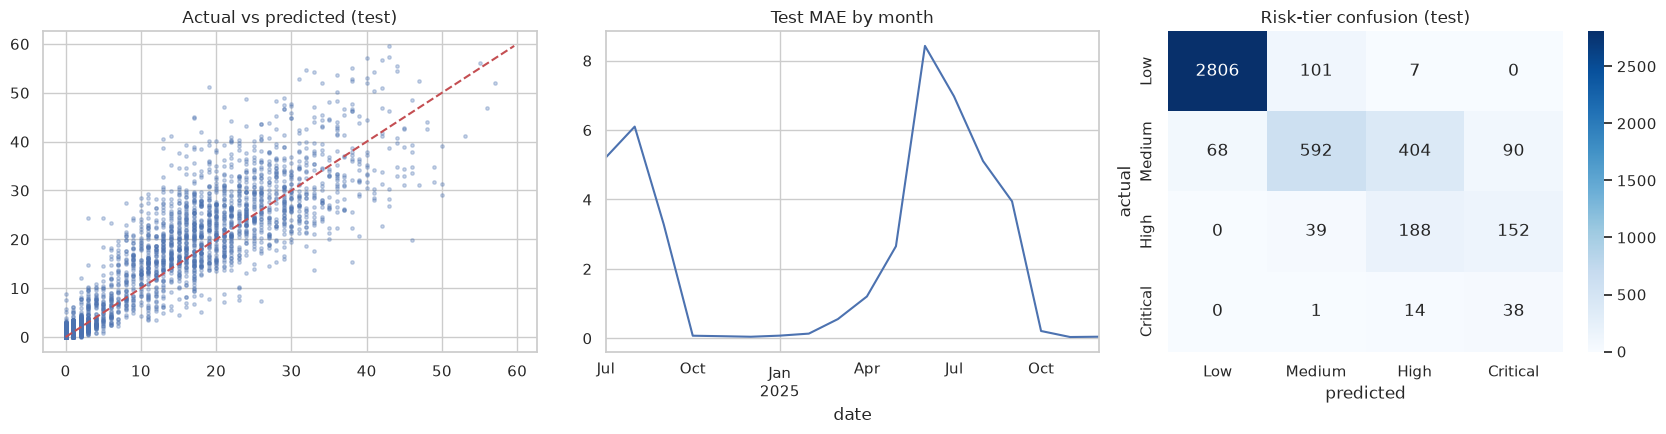

In [13]:
tp = pd.read_csv(ROOT/'reports/test_predictions.csv', parse_dates=['date'])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(tp.actual, tp.pred, s=6, alpha=.3); mx = tp[['actual','pred']].max().max(); ax[0].plot([0,mx],[0,mx],'r--'); ax[0].set_title('Actual vs predicted (test)')
(tp.assign(ae=(tp.actual-tp.pred).abs()).groupby(tp.date.dt.to_period('M')).ae.mean()).plot(ax=ax[1], title='Test MAE by month')
cm = np.array(M['test_by_window'][C.MAIN_WINDOW]['tier_confusion']); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=C.RISK_TIERS, yticklabels=C.RISK_TIERS, ax=ax[2]); ax[2].set_xlabel('predicted'); ax[2].set_ylabel('actual'); ax[2].set_title('Risk-tier confusion (test)')
plt.tight_layout(); plt.show()

### Prediction intervals
Scaled residuals |y-p|/sqrt(p+1) from chronological out-of-fold forecasts, calibrated separately per predicted-risk tier with separate lower/upper constants (Mondrian conformal). The interval always contains the point forecast. **Limitations:** exchangeability is assumed between the calibration folds and deployment, interval coverage conditional on the *actual* outcome tier is not guaranteed, and coverage can degrade under distribution shift.

In [14]:
t = M['test_by_window'][C.MAIN_WINDOW]; t0 = M['test_by_window_original_method'][C.MAIN_WINDOW]
print('improved :', {k: round(t[k],3) for k in ['interval_coverage','interval_width','interval_coverage_actual_critical']})
print('original :', {k: round(t0[k],3) for k in ['interval_coverage','interval_width','interval_coverage_actual_critical']})
display(pd.read_csv(ROOT/'reports/test_by_actual_tier.csv')[['actual_tier','n','mean_actual','MAE','interval_coverage','interval_width']].round(3))
display(pd.read_csv(ROOT/'reports/test_by_pred_tier.csv')[['pred_tier','n','mean_actual','MAE','interval_coverage','interval_width']].round(3))

improved : {'interval_coverage': 0.91, 'interval_width': 11.925, 'interval_coverage_actual_critical': 0.943}
original : {'interval_coverage': 0.949, 'interval_width': 13.313, 'interval_coverage_actual_critical': 0.472}


,actual_tier,n,mean_actual,MAE,interval_coverage,interval_width
0,Low,2914,0.988,0.761,0.925,3.225
1,Medium,1154,17.718,5.802,0.856,26.095
2,High,379,31.836,6.415,0.963,32.434
3,Critical,53,45.151,10.014,0.943,35.017


,pred_tier,n,mean_actual,MAE,interval_coverage,interval_width
0,Low,2874,1.045,0.620,0.922,2.585
1,Medium,733,15.820,4.388,0.928,23.748
2,High,613,23.710,6.438,0.896,30.579
3,Critical,280,30.900,10.455,0.779,35.999


### Drivers: grouped permutation importance (validation, rise in MAE when a group is shuffled)

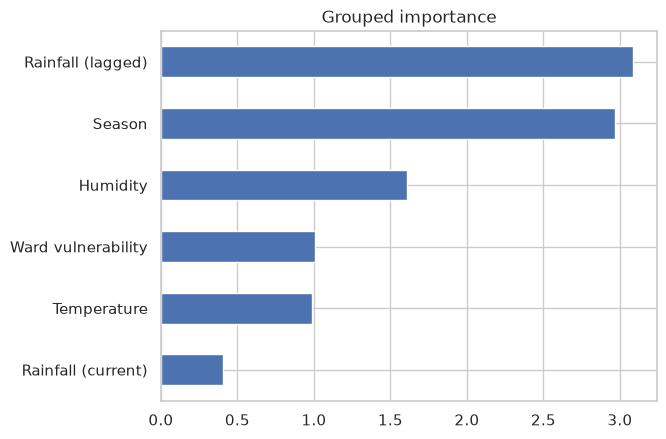

In [15]:
pd.Series(M['grouped_importance_val_MAE_increase']).sort_values().plot.barh(title='Grouped importance'); plt.show()

### Example inference (what the dashboard calls)

In [16]:
from src.predict import load_features, predict_one, explain_row
F = load_features()
print(predict_one(F, 'DNCC_Ward_01', '2025-08-04'))
explain_row(F[(F.ward_id=='DNCC_Ward_01')&(F.date=='2025-08-04')]).round(2)

{'ward_id': 'DNCC_Ward_01', 'date': '2025-08-04', 'window': 'Weeks 2-4 ahead (total)', 'predicted_cases': np.float64(28.42), 'interval_80': [np.float64(15.6), np.float64(48.1)], 'risk_tier': 'High'}


,driver,effect_cases
0,Ward vulnerability,5.29
1,Rainfall (lagged),0.45
2,Rainfall (current),0.00
3,Season,0.00
4,Humidity,-0.32
5,Temperature,-2.94


## 6. Automated leakage audit and synthetic-data check
Impressive metrics are only meaningful if the pipeline cannot cheat. `src/audit.py` runs five checks using **training/validation data only** (the test period is never touched):
1. **Causal direction** – cases should correlate more with *past* rain at a 2-4 week lag than with *future* rain.
2. **Permutation placebo** – shuffle the target within each ward; a leak-free pipeline must collapse to R² ≈ 0.
3. **Ablations** – how much do ward attributes + season explain *without any weather*?
4. **Ward × week-of-year climatology** – a much stronger seasonal reference than "same week last year".
5. **Synthetic signature** – R² > 0.9 is unusual for real surveillance data.

In [17]:
from src import audit
import pandas as pd
A = audit.leakage_audit()
pd.DataFrame({'past rain lag (w)': A['corr_cases_vs_past_rain_lag']}).T.round(3).style.set_caption('corr(cases_t, rain_{t-k}) averaged over wards')


,0,1,2,3,4,5,6
past rain lag (w),0.553000,0.613000,0.697000,0.779000,0.707000,0.562000,0.515000


In [18]:
print('Future-rain lead correlations (confounded by shared seasonality):', {k: round(v,2) for k,v in A['corr_cases_vs_future_rain_lead'].items()})
rows = {k: A[k] for k in ['placebo_shuffled_target_val','static_plus_season_only_val','ward_week_climatology_val','full_weather_model_val']}
names = {'placebo_shuffled_target_val':'Placebo (shuffled target)','static_plus_season_only_val':'Ward attributes + season only (no weather)',
         'ward_week_climatology_val':'Ward x week-of-year climatology','full_weather_model_val':'Full weather-lag model'}
tab = pd.DataFrame(rows).T.rename(index=names).round(3); display(tab)
gain = 1 - A['full_weather_model_val']['MAE'] / A['ward_week_climatology_val']['MAE']
print(f"Weather-lag features cut validation MAE by {gain:.0%} versus the strongest seasonal reference; the placebo R2 = {A['placebo_shuffled_target_val']['R2']:.2f} confirms no target leakage.")
print('Residual lag-1 autocorrelation (val):', round(A['val_residual_lag1_autocorr_mean'],2), '(overlapping 3-week target windows induce some of this)')


Future-rain lead correlations (confounded by shared seasonality): {1: 0.49, 2: 0.46, 3: 0.37, 4: 0.29}


,MAE,RMSE,R2
Placebo (shuffled target),9.863,13.032,0.041
Ward attributes + season only (no weather),2.556,5.535,0.827
Ward x week-of-year climatology,2.590,5.635,0.821
Full weather-lag model,1.856,3.891,0.915


Weather-lag features cut validation MAE by 28% versus the strongest seasonal reference; the placebo R2 = 0.04 confirms no target leakage.
Residual lag-1 autocorrelation (val): 0.55 (overlapping 3-week target windows induce some of this)


**Interpretation.** Past-rain correlation peaks at a **3-week lag**, matching the 2-4 week breeding clock, and exceeds future-rain correlation (which only reflects shared seasonality). The shuffled-target placebo collapses to R² ≈ 0, so features contain no target leakage. Note, however, that ward attributes + season alone already reach R² ≈ 0.83: **most of the explainable signal is ward vulnerability × seasonality, and lagged weather adds a further ~30% MAE reduction**. Together with R² > 0.9 on validation, this is the signature of a **synthetic dataset** – results are an upper bound for the method, not evidence of real-world accuracy, and must be re-validated on real surveillance data.

## 7. Hyper-parameter check (validation only)
Twelve random configurations of the selected HistGradientBoosting-Poisson model are compared with the default on the **validation** period. A tuned configuration is adopted only if it beats the default by more than 2% MAE (otherwise the simpler, already-validated default stays, avoiding validation over-fitting).

In [19]:
H = audit.tune_hgb(n_iter=12)
display(H.head(6).round(3))
d = float(H.loc[H.name=='default','MAE'].iloc[0]); b = float(H.MAE.iloc[0]); rel = (d-b)/d
print(f"Default MAE {d:.3f} vs best tuned {b:.3f} -> gain {rel:.1%}; adopted: {rel>0.02}")


,name,max_leaf_nodes,learning_rate,max_iter,min_samples_leaf,l2_regularization,MAE,RMSE,R2,fit_s
0,rs7,8,0.08,500,30,5.0,1.831,3.783,0.919,1.5
1,rs5,24,0.05,500,60,1.0,1.839,3.860,0.916,1.8
2,rs4,16,0.05,200,100,10.0,1.842,3.832,0.917,1.3
3,rs10,24,0.03,300,30,1.0,1.845,3.844,0.917,2.2
4,rs9,32,0.05,500,60,10.0,1.847,3.866,0.916,2.3
5,rs8,8,0.08,500,30,0.0,1.848,3.818,0.918,1.7


Default MAE 1.856 vs best tuned 1.831 -> gain 1.3%; adopted: False


## 7b. Early-outbreak detection: original vs improved, false negatives, calibration, forecast strategy, input quality
All thresholds / calibration use validation-side (chronological, pre-test) data only; test numbers are reporting only. Ranking quality (PR-AUC) is unchanged by the new rule - the gain is a different operating point and is paid for with more false alarms.

In [20]:
cmp_ = pd.read_csv(ROOT/'reports/risk_comparison_original_vs_improved.csv')
display(cmp_[['window','method','HC_decision_cut','HC_recall','HC_precision','HC_FN','HC_FP','HC_false_alarm_rate','HC_flagged_share','CRIT_recall','CRIT_FN','HC_PR_AUC','interval_coverage','interval_coverage_actual_critical','interval_width']].round(3))
print('Missed outbreaks (main window):'); display(pd.read_csv(ROOT/'reports/missed_outbreaks_analysis.csv'))
print('Do other scorers rank High/Critical weeks better? (OOF 2019-2023)'); display(pd.read_csv(ROOT/'reports/risk_scorer_alternatives_oof.csv').round(3))
print('By season (improved rule):'); display(pd.read_csv(ROOT/'reports/test_by_season.csv')[['season','n','HC_prevalence','HC_recall','HC_FN','HC_false_alarm_rate','interval_coverage']].round(3))

,window,method,HC_decision_cut,HC_recall,HC_precision,HC_FN,HC_FP,HC_false_alarm_rate,HC_flagged_share,CRIT_recall,CRIT_FN,HC_PR_AUC,interval_coverage,interval_coverage_actual_critical,interval_width
0,Weeks 2-4 ahead (total),original,27.000,0.706,0.548,127,252,0.062,0.124,0.415,31,0.656,0.949,0.472,13.313
1,Weeks 2-4 ahead (total),improved,22.275,0.907,0.439,40,501,0.123,0.198,0.717,15,0.656,0.910,0.943,11.925
2,Week 2 ahead,original,10.000,0.488,0.609,229,140,0.035,0.080,0.270,81,0.581,0.948,0.550,5.181
3,Week 2 ahead,improved,7.750,0.783,0.476,97,385,0.095,0.163,0.595,45,0.581,0.930,0.892,5.842
4,Week 3 ahead,original,10.000,0.471,0.547,230,170,0.042,0.083,0.206,85,0.549,0.964,0.598,5.560
5,Week 3 ahead,improved,7.500,0.793,0.430,90,458,0.113,0.178,0.542,49,0.549,0.918,0.963,5.847
6,Week 4 ahead,original,10.000,0.432,0.472,231,197,0.048,0.083,0.072,90,0.467,0.961,0.546,5.702
7,Week 4 ahead,improved,8.000,0.720,0.406,114,429,0.105,0.160,0.433,55,0.467,0.920,0.907,6.616


Missed outbreaks (main window):


,rule,missed_High_or_Critical,of_actual_HC,median_pred_over_actual,share_in_onset_week,share_caught_by_watch_flag,months,top_wards,by_city
0,original rule (pred >= High cut),127,432,0.760110,0.519685,0.952756,"{""6"": 20, ""7"": 56, ""8"": 46, ""9"": 5}","{""CCC_Ward_04"": 8, ""DNCC_Ward_15"": 7, ""DSCC_Wa...","{""Dhaka North"": 39, ""Dhaka South"": 39, ""Chatto..."
1,escalated High+ (pred >= escalated threshold),40,432,0.671773,0.650000,0.850000,"{""6"": 4, ""7"": 23, ""8"": 12, ""9"": 1}","{""CCC_Ward_04"": 4, ""DSCC_Ward_01"": 3, ""DSCC_Wa...","{""Dhaka South"": 15, ""Chattogram"": 11, ""Dhaka N..."


Do other scorers rank High/Critical weeks better? (OOF 2019-2023)


,scorer,oof_n,oof_pos,PR_AUC,recall_at_FAR5,recall_at_FAR10
0,Poisson regression (shipped),15600,1870,0.820,0.805,0.923
1,HistGB classifier P(y>=High),15600,1870,0.830,0.803,0.924
2,HistGB 70th-percentile quantile,15600,1870,0.836,0.817,0.941


By season (improved rule):


,season,n,HC_prevalence,HC_recall,HC_FN,HC_false_alarm_rate,interval_coverage
0,Dry (Dec-May),1620,0.000,NaN,0,0.000,0.908
1,Monsoon (Jun-Sep),1920,0.225,0.907,40,0.337,0.868
2,Post-monsoon (Oct-Nov),960,0.000,NaN,0,0.000,1.000


In [21]:
cal = pd.read_csv(ROOT/'reports/interval_calibration_test.csv')
print('80% interval coverage by predicted-risk quintile (test):')
cal.round(3)

80% interval coverage by predicted-risk quintile (test):


,bin,n,mean_pred,mean_actual,coverage,width
0,0,900,0.018,0.026,1.000,1.531
1,1,900,0.071,0.052,0.996,1.624
2,2,900,1.800,1.703,0.844,3.710
3,3,900,15.089,14.290,0.854,20.519
4,4,900,30.739,25.913,0.858,32.238


In [22]:
hs = pd.read_csv(ROOT/'reports/horizon_strategy_validation.csv')
print('Mean validation MAE by strategy:'); print(hs.groupby('strategy').MAE.mean().round(3).to_string())
hs.round(3)

Mean validation MAE by strategy:
strategy
derived (window/3)           1.101
direct (per-horizon)         1.006
pooled (+horizon feature)    1.008


,horizon_weeks,strategy,n,MAE,RMSE,R2
0,2,direct (per-horizon),4440,0.916,2.038,0.825
1,2,pooled (+horizon feature),4440,0.923,2.061,0.821
2,2,derived (window/3),4440,1.039,2.272,0.782
3,3,direct (per-horizon),4440,0.965,2.139,0.807
4,3,pooled (+horizon feature),4440,0.948,2.076,0.818
5,3,derived (window/3),4440,0.977,2.110,0.812
6,4,direct (per-horizon),4440,1.138,2.411,0.755
7,4,pooled (+horizon feature),4440,1.154,2.511,0.734
8,4,derived (window/3),4440,1.288,2.702,0.692


In [23]:
from src.quality import data_quality_report
print(json.dumps(data_quality_report(raw), indent=1))

{
 "rows": 31320,
 "wards": 60,
 "date_min": "2016-01-04",
 "date_max": "2025-12-29",
 "duplicate_ward_weeks": 0,
 "missing_cells": {
  "avg_temp_c": 0,
  "rainfall_mm": 0,
  "relative_humidity_pct": 0,
  "dengue_cases": 0
 },
 "wards_with_calendar_gaps": 0,
 "negative_values": 0,
 "humidity_out_of_range": 0,
 "zero_case_share": 0.5803320561941252
}


## 8. Operational inference: multi-week forecast and what-if scenario
`src/scenario.py` rebuilds the lag features from a raw 9-week weather history with the *same* feature code and bundle used in training and in the dashboard. Below: the multi-week forecast (with 80% intervals) for one ward, and the effect of a hypothetical heavy-rain event in the last 4 weeks.

,window,pred,lo,hi,tier,alert
0,Weeks 2-4 ahead (total),28.4,15.6,48.1,High,True
1,Week 2 ahead,9.3,4.2,18.3,High,True
2,Week 3 ahead,9.6,4.5,19.4,High,True
3,Week 4 ahead,8.8,3.3,20.4,High,True


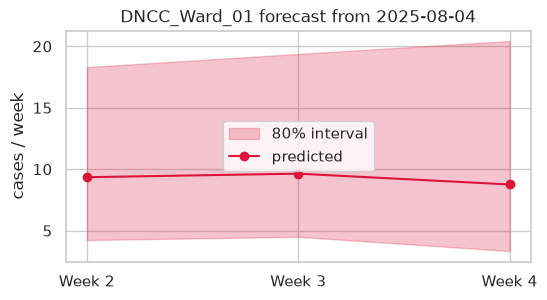

observed weather         ->   28.4 cases (16-48), tier High
rain x0 (last 5 wks)     ->    4.9 cases (3-9), tier Low
rain x2 (last 5 wks)     ->   50.8 cases (33-69), tier Critical


In [24]:
import matplotlib.pyplot as plt, pandas as pd
from src import config as C
from src.predict import load_bundle, load_features
from src.scenario import all_horizons, apply_scenario, predict_history, ward_history
Bn, F = load_bundle(), load_features()
ward, date = 'DNCC_Ward_01', pd.Timestamp('2025-08-04')
mh = all_horizons(F[(F.ward_id==ward)&(F.date==date)], Bn)
display(mh.round(1))
wk = mh[mh.window.str.match(r"^Week \d")]
fig, ax = plt.subplots(figsize=(6,3)); x = range(len(wk))
ax.fill_between(x, wk.lo, wk.hi, alpha=.25, color='crimson', label='80% interval'); ax.plot(x, wk.pred, 'o-', color='crimson', label='predicted')
ax.set_xticks(list(x)); ax.set_xticklabels(['Week 2','Week 3','Week 4']); ax.set_ylabel('cases / week'); ax.set_title(f'{ward} forecast from {date.date()}'); ax.legend(); plt.show()
h = ward_history(F, ward, date)
for name, hh in {'observed weather': h, 'rain x0 (last 5 wks)': apply_scenario(h, 0.0, weeks=5), 'rain x2 (last 5 wks)': apply_scenario(h, 2.0, weeks=5)}.items():
    r = predict_history(hh, bundle=Bn); print(f"{name:24s} -> {r['pred']:6.1f} cases ({r['lo']:.0f}-{r['hi']:.0f}), tier {r['tier']}")


In [25]:
b, b0 = M['test_by_window'][C.MAIN_WINDOW], M['test_by_window_original_method'][C.MAIN_WINDOW]
print(f"Test MAE {b['MAE']:.2f} vs {b['baselines']['Seasonal-naive (52w earlier)']['MAE']:.2f} (seasonal-naive) and {b['baselines']['Persistence (cases_t x horizons)']['MAE']:.2f} (persistence); R2 {b['R2']:.2f}")
print(f"High/Critical missed: {b0['HC_FN']} -> {b['HC_FN']} of {b['HC_TP']+b['HC_FN']}; recall {b0['HC_recall']:.0%} -> {b['HC_recall']:.0%}; precision {b0['HC_precision']:.0%} -> {b['HC_precision']:.0%}; false-alarm rate {b0['HC_false_alarm_rate']:.1%} -> {b['HC_false_alarm_rate']:.1%}")
print(f"Interval coverage on weeks that turned out Critical: {b0['interval_coverage_actual_critical']:.0%} -> {b['interval_coverage_actual_critical']:.0%}; overall {b0['interval_coverage']:.0%} -> {b['interval_coverage']:.0%} (nominal 80%)")

Test MAE 2.64 vs 4.03 (seasonal-naive) and 6.22 (persistence); R2 0.81
High/Critical missed: 127 -> 40 of 432; recall 71% -> 91%; precision 55% -> 44%; false-alarm rate 6.2% -> 12.3%
Interval coverage on weeks that turned out Critical: 47% -> 94%; overall 95% -> 91% (nominal 80%)


## Caveats
- The data look synthetic (very high R2, clean lag-3 peak, autocorrelated residuals): results are an upper bound for the method, not real-world dengue-forecasting evidence.
- Tier cut-points are relative (training-set 70/90/97th percentiles of the window total), not clinical or official thresholds.
- The High/Critical decision thresholds were chosen with a false-alarm budget on out-of-fold data; the budget was *not* preserved on the test period (season-level shifts), see the tables above.
- The test period was evaluated once per window; nothing was tuned on it.